### Set autoreloading
This extension will automatically update with any changes to packages in real time

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import os, sys
sys.path.append('/home/hnayak/.conda/envs/NugraphBase/lib/python3.10/site-packages')

In [4]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the data
file_path = "/scratch/7DayLifetime/cerati/numiallwr2.half.gnn.h5"
file = h5py.File(file_path, 'r')
dataset_group = file['dataset']

# Set up lists to hold the combined arrays for ALL planes
combined_time = []
combined_rms = []
planes = ['u', 'v', 'y']

print("Aggregating data across all events and all planes...")

for key in dataset_group.keys():
    data = dataset_group[key][()]
    
    # Loop through planes and add them all to the same list
    for plane in planes:
        valid_mask = data[f'{plane}/y_semantic'] > -1
        filtered_time = data[f'{plane}/pos'][valid_mask, 1]
        combined_time.append(filtered_time)
        filtered_rms = data[f'{plane}/x'][valid_mask, 1]
        combined_rms.append(filtered_rms)

# Concatenate everything into single massive 1D arrays
combined_time = np.concatenate(combined_time)
combined_rms = np.concatenate(combined_rms)



Aggregating data across all events and all planes...


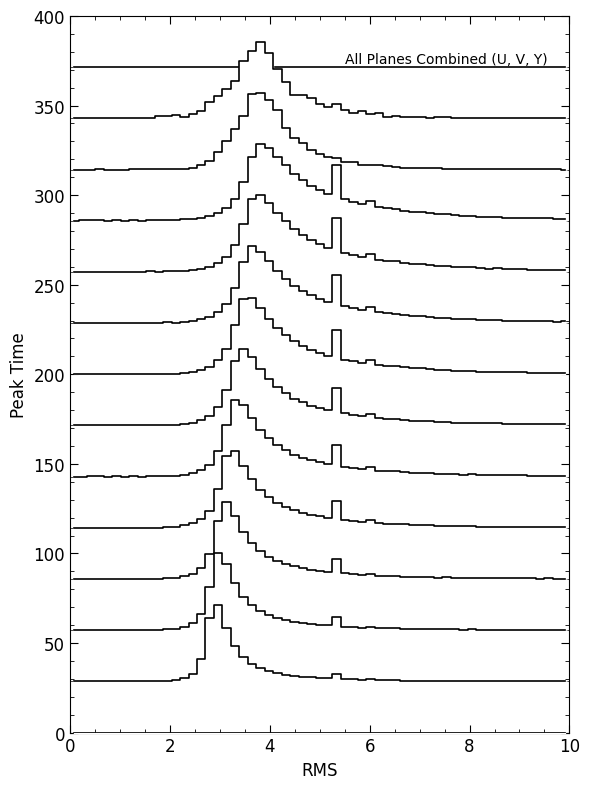

In [5]:
# ==========================================
# 2. Setup the Ridge Plot Parameters
# ==========================================
# Define the bins for the Y-axis (Drift Time slices)
y_min_val, y_max_val = 0, 400
y_bins = np.linspace(y_min_val, y_max_val, num=15) # 40 ridges
y_step = y_bins[1] - y_bins[0]  # Calculate the distance between ridges

# Define the bins for the X-axis (The RMS distribution)
x_min_val, x_max_val = 0, 10
x_bins = np.linspace(x_min_val, x_max_val, num=60)
x_centers = (x_bins[:-1] + x_bins[1:]) / 2

# Create a single figure
fig, ax = plt.subplots(figsize=(6, 8))

# ==========================================
# 3. Build the Ridges
# ==========================================
# Overlap factor: 1.5 means the tallest peak in a ridge will reach halfway into the ridge above it
overlap_factor = 1.5 

# Loop from top to bottom so lower ridges are drawn last (appearing in front)
for i in reversed(range(len(y_bins) - 1)):
    y_start = y_bins[i]
    y_end = y_bins[i+1]
    
    # Isolate the data that falls into this specific time slice
    mask = (combined_time >= y_start) & (combined_time < y_end)
    slice_data = combined_rms[mask]
        
    # Calculate the histogram for this slice
    hist, _ = np.histogram(slice_data, bins=x_bins)
    
    # Scale the histogram dynamically based on the y_step
    if hist.max() > 0:
        # Normalizes to 0-1, then scales to fit the vertical spacing
        hist_scaled = (hist / hist.max()) * (y_step * overlap_factor)
    else:
        hist_scaled = hist
        
    # The vertical baseline for this specific ridge
    y_offset = y_start 
    
    # Plot 1: The dashed baseline
    ax.plot([x_min_val, x_max_val], [y_offset, y_offset], color='black', linestyle='--', linewidth=0.5, zorder=len(y_bins)-i)
    
    # Plot 2: The solid white fill (hides lines behind it)
    ax.fill_between(x_centers, y_offset, hist_scaled + y_offset, step='mid', color='white', zorder=len(y_bins)-i)
    
    # Plot 3: The black stepped outline
    ax.step(x_centers, hist_scaled + y_offset, where='mid', color='black', linewidth=1.2, zorder=len(y_bins)-i)

# ==========================================
# 4. Styling
# ==========================================
ax.set_xlim(x_min_val, x_max_val)
ax.set_ylim(y_min_val, y_max_val)

# CORRECTED: Changed label to reflect raw RMS values
ax.set_xlabel("RMS", fontsize=12)
ax.set_ylabel("Peak Time", fontsize=12)

# Add minor ticks
ax.minorticks_on()
ax.tick_params(which='both', direction='in', top=True, right=True)
ax.tick_params(which='major', length=6, labelsize=12)
ax.tick_params(which='minor', length=3)

# Add text box indicating all planes are combined
ax.text(0.55, 0.95, "All Planes Combined (U, V, Y)", 
        transform=ax.transAxes, verticalalignment='top',horizontalalignment='left', fontsize=10)

plt.tight_layout()
plt.savefig("rms_time_combinedplanes.pdf", format='pdf')
plt.savefig("rms_time_combinedplanes.png", format='png')
plt.show()

In [5]:
len(file['dataset'])

173154

In [ ]:
break

### Import packages
We'll need the `nugraph` and `pynuml` packages imported in order to plot, and `torch` for some tensor operations later on

In [6]:
import os
import nugraph as ng
import pynuml
import torch

### Set model and data to use

This allows the user to switch out different model architectures and datasets

In [7]:
# ckpt = os.path.expandvars("$NUGRAPH_DATA/uboone-opendata/hierarchical.ckpt")
ckpt = "/home/hnayak/NuGraphLogs/NuGraphMain/DA-DANN/uBooNE-Tiny-Data-2026-06-18-19/version_0/checkpoints/epoch=1-step=138.ckpt"
model = Model.load_from_checkpoint(ckpt, map_location="cpu")
model.freeze()

NameError: name 'Model' is not defined

In [ ]:
Data = ng.data.NuGraphDataModule
Model = ng.models.NuGraph3

### Configure data module
Declare a data module. If you're working on a standard cluster, the data file location should be configured automatically. If not, you'll need to configure it manually.

In [ ]:
data_source_path = "/scratch/7DayLifetime/cerati/concat-final-makeup.tiny.gnn.h5"
data_target_path= "/scratch/7DayLifetime/cerati/icarus_numi_2d.gnn.h5"
nudata = Data(data_source_path=data_source_path, data_target_path=data_target_path, model=Model)

### Configure network
In order to test a trained model, we instantiate it using a checkpoint file. These are produced during training, so if you've trained a model, there should be an associated checkpoint in your output directory that you can pass here.

## Configure plotting utility
Instantiate the **pynuml** utility for plotting graph objects, which will do the heavy lifting for us here!

In [ ]:
plot = pynuml.plot.GraphPlot(planes=nudata.planes,
                             classes=nudata.semantic_classes)

## Plot ground truth labels

### Iterable dataset

First we define an iterator over the test dataset:

In [ ]:
test_iter = iter(nudata.test_dataset)

### Retrieve the next graph

This block retrieves a graph from the testing dataset, and passes it through the trained model. Since we defined `test_iter` as an iterator over the dataset, the following block can be executed multiple times, and each time it's executed, it will step to the next graph in the dataset.

In [ ]:
data = next(test_iter)
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
model(data);

### Plot a single graph

We can now use pynuml's plotting utilities to plot the graph as a figure. Each time you call the above block to retrieve a new graph, you can then re-execute the plotting blocks to re-plot with the new graph.

In [ ]:
fig = plot.plot(data, target='semantic', how='true', filter='show')
fig

### Save plots to disk

We can also use plotly's `write_html` and `write_image` methods to print the figure as an interactive webpage, or in a raster graphics (ie. PNG, JPEG etc) or vector graphics (ie. PDF) format. By default this writes to a `plots` subdirectory – if you're seeing an error that this directory does not exist, simply create one, or change the path to a valid output location!

In [ ]:
fig.write_html(f'plots/evd/{name}_semantic_true.html')
fig.write_image(f'plots/evd/{name}_semantic_true.png')
fig.write_image(f'plots/evd/{name}_semantic_true.pdf')

### (Optional) Select example events

The following blocks will select the representative events from the NuGraph2 paper

### Event 1

Run 5189, subrun 225, event 11300

In [ ]:
data = nudata.test_dataset[64]
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
model.step(data);

### Event 2

Run 6999, subrun 11, event 595

In [ ]:
data = nudata.test_dataset[36]
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
model.step(data);

### Event 3

Run 7048, subrun 177, event 8858

In [ ]:
data = nudata.test_dataset[11]
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
model.step(data);

### Event 4

Run 5459, subrun 94, event 4738

In [ ]:
data = nudata.test_dataset[91]
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
model.step(data);

### Event 5

Run 6780, subrun 200, event 10006

In [ ]:
data = nudata.test_dataset[27]
md = data['metadata']
name = f'r{md.run}_sr{md.subrun}_e{md.event}'
model.step(data);

### Plot event displays

Write event displays to disk in PDF format for use in the NuGraph2 paper.

In [ ]:
plot.plot(data, target='filter', how='true', filter='none').write_image(f'plots/evd/{name}_filter_true.pdf')
plot.plot(data, target='filter', how='pred', filter='none').write_image(f'plots/evd/{name}_filter_pred.pdf')
plot.plot(data, target='semantic', how='true', filter='true').write_image(f'plots/evd/{name}_semantic_true.pdf')
plot.plot(data, target='semantic', how='pred', filter='pred').write_image(f'plots/evd/{name}_semantic_pred.pdf')

### Print model performance

Print out information on the rate at which the model makes mistakes, and some information on common failure modes.

In [ ]:
tf = torch.cat([(data[p].y_semantic!=-1) for p in nudata.planes])
pf = torch.cat([data[p].x_filter.round() for p in nudata.planes])
ts = torch.cat([data[p].y_semantic for p in nudata.planes])[tf]
ps = torch.cat([data[p].x_semantic.argmax(dim=1) for p in nudata.planes])[tf]

print(f'there are {tf.size(0)} hits overall, of which {tf.sum()} are signal.')

print('\n### Filter\n')

mask = tf != pf
print(f'{mask.sum()} hits were classified wrong. of those, {(tf[mask]==0).sum()} are false positives, and {(tf[mask]==1).sum()} are false negatives.')

print('\n### Semantic\n')

print(f'of the {tf.sum()} signal hits, {(ps==ts).sum()} are correctly classified.')

mask = ts != ps
print(f'of the {mask.sum()} misclassified hits:')

for i, c in enumerate(nudata.semantic_classes):
    tm = ts[mask]==i
    if tm.sum() == 0: continue
    print(f'- {tm.sum()} {c} hits were misclassified.')
    for j, cj in enumerate(nudata.semantic_classes):
        pm = ps[mask][tm]==j
        if pm.sum() == 0: continue
        print(f'  - {pm.sum()} as {cj}')